In [ ]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler, LabelEncoder

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
TANGGAL_ACUAN = pd.Timestamp('2026-11-11')   # tanggal pengerjaan, dipakai untuk mengecek tanggal di masa depan

Tahap 1. Memuat data dan identifikasi masalah awal

In [ ]:
df_raw = pd.read_csv('/content/drive/MyDrive/PD_PM/dataset_Properti_Jatim (1).csv', dtype=str, keep_default_na=False)
print('Ukuran data:', df_raw.shape)
display(df_raw.head())

Ukuran data: (198, 19)


,No,ID_Properti,Nama_Agen,Provinsi,Kota,Tipe_Properti,Luas_Tanah,Luas_Bangunan,Jumlah_Kamar_Tidur,Jumlah_Kamar_Mandi,Jumlah_Lantai,Tahun_Dibangun,Sertifikat,Kondisi,Jarak_ke_Pusat_Kota_km,Fasilitas,Tanggal_Listing,Harga_per_m2_Tanah,Harga_Jual
0,1,PRP-052,Eko Properti,Jawa Timur,Gresik,Rumah,86.0,52.0,2,2,2,2006,Girik,Baru,9.4,"Taman, Water Heater, Mushola",21/09/2026,7837000.0,Rp 674.000.000
1,2,PRP-039,Rina Land,Jawa Timur,Kota Malang,,168.0,86.0,3,1,1,2000,SHM,Baik,5.1,"Keamanan 24 Jam, AC",2026-05-15,8631000.0,1450000000.0
2,3,PRP-182,Sari Realty,Jawa Timur,batu,Rumah,171.0,141.0,4,2,1,2001,SHM,Baru,2.0,"Taman, AC",2026-04-14,11088000.0,1896000000.0
3,4,PRP-145,Rina Properti,Jawa Timur,malang,Rmh,124 meter,,3,2,2,2015,hgb,Perlu Renovasi,1.9,"AC, WATER HEATER, TAMAN, GARASI",20/09/2025,9944000.0,"1,23 M"
4,5,PRP-065,Dewi Properti,Jawa Timur,Surabaya,Rumah,152m²,110.0,4,,1,1997,HGB,baik,10.6,Keamanan 24 Jam,1 Juni 2026,12283000.0,1867000000.0


In [ ]:
kolom_numerik = ['Luas_Tanah','Luas_Bangunan','Jumlah_Kamar_Tidur','Jumlah_Kamar_Mandi','Jumlah_Lantai',
                 'Tahun_Dibangun','Jarak_ke_Pusat_Kota_km','Harga_per_m2_Tanah','Harga_Jual']
kolom_kategorik = ['Nama_Agen','Provinsi','Kota','Tipe_Properti','Sertifikat','Kondisi','Fasilitas']
PENANDA_KOSONG = ['-', 'belum ada data', 'tidak ada info', 'kemarin']

baris = []
for c in df_raw.columns:
    s = df_raw[c]
    st = s.str.strip()
    kosong = (st == '').sum()
    penanda = st.str.lower().isin(PENANDA_KOSONG).sum()
    non_angka = 0
    if c in kolom_numerik:
        non_angka = ((st != '') & ~st.str.fullmatch(r'-?\d+(\.\d+)?')).sum()
    baris.append({'Kolom': c, 'Sel kosong': kosong, 'Penanda kosong teks': penanda,
                  'Isi non-angka (kolom numerik)': non_angka,
                  'Spasi berlebih': (s != st).sum(), 'Jumlah nilai unik': st.nunique()})
masalah_awal = pd.DataFrame(baris).set_index('Kolom')
display(masalah_awal)
print('ID_Properti duplikat :', df_raw['ID_Properti'].duplicated().sum(), 'baris')
print('Baris identik (selain kolom No):', df_raw.drop(columns='No').duplicated().sum(), 'baris')

,Sel kosong,Penanda kosong teks,Isi non-angka (kolom numerik),Spasi berlebih,Jumlah nilai unik
Kolom,,,,,
No,0,0,0,0,198
ID_Properti,0,0,0,0,188
Nama_Agen,0,0,0,8,18
Provinsi,0,0,0,0,1
Kota,9,0,0,8,22
Tipe_Properti,7,0,0,7,12
Luas_Tanah,8,0,40,0,136
Luas_Bangunan,11,0,24,0,116
Jumlah_Kamar_Tidur,9,0,3,0,13


ID_Properti duplikat : 10 baris
Baris identik (selain kolom No): 6 baris


Tahap 2. Standardisasi penanda missing dan spasi berlebih

In [ ]:
df = df_raw.copy()
for c in df.columns:
    df[c] = df[c].str.strip()
df = df.apply(lambda s: s.where(~s.str.lower().isin(['',] + PENANDA_KOSONG)))
df['No'] = df['No'].astype(int)
missing_awal = df.isna().sum()
display(missing_awal[missing_awal > 0].to_frame('Missing asli'))

,Missing asli
Kota,9
Tipe_Properti,7
Luas_Tanah,8
Luas_Bangunan,11
Jumlah_Kamar_Tidur,9
Jumlah_Kamar_Mandi,12
Tahun_Dibangun,16
Sertifikat,18
Kondisi,14
Jarak_ke_Pusat_Kota_km,13


Tahap 3. Perbaikan tipe data dan format

In [ ]:
KATA_ANGKA = {'satu':'1','dua':'2','tiga':'3','empat':'4','lima':'5'}

def ke_angka(s):
    s = s.str.lower().replace(KATA_ANGKA).str.replace(',', '.', regex=False)
    return pd.to_numeric(s.str.extract(r'(-?\d+(?:\.\d+)?)')[0], errors='coerce')

def ke_rupiah(x):
    if pd.isna(x): return np.nan
    x = x.strip()
    if x.startswith('Rp'):
        return float(x.replace('Rp','').replace('.','').strip())
    m = re.fullmatch(r'([\d,]+)\s*(M|jt|T)', x)
    if m:
        return float(m.group(1).replace(',', '.')) * {'M':1e9, 'jt':1e6, 'T':1e12}[m.group(2)]
    return float(x)

BULAN = {'januari':1,'februari':2,'maret':3,'april':4,'mei':5,'juni':6,'juli':7,'agustus':8,
         'september':9,'oktober':10,'november':11,'desember':12}

def ke_tanggal(x):
    if pd.isna(x): return pd.NaT
    try:
        if re.fullmatch(r'\d{4}-\d{2}-\d{2}', x): return pd.Timestamp(x)
        m = re.fullmatch(r'(\d{2})/(\d{2})/(\d{4})', x)
        if m: return pd.Timestamp(int(m[3]), int(m[2]), int(m[1]))
        m = re.fullmatch(r'(\d{2})\.(\d{2})\.(\d{2})', x)
        if m: return pd.Timestamp(2000 + int(m[3]), int(m[2]), int(m[1]))
        m = re.fullmatch(r'(\d{2})-(\d{2})-(\d{4})', x)
        if m:
            a, b, y = int(m[1]), int(m[2]), int(m[3])
            return pd.Timestamp(y, a, b) if b > 12 else pd.Timestamp(y, b, a)
        m = re.fullmatch(r'(\d{1,2}) ([A-Za-z]+) (\d{4})', x)
        if m: return pd.Timestamp(int(m[3]), BULAN[m[2].lower()], int(m[1]))
    except Exception:
        return pd.NaT
    return pd.NaT

sebelum = df.copy()
for c in ['Luas_Tanah','Luas_Bangunan','Jumlah_Kamar_Tidur','Jumlah_Kamar_Mandi','Jumlah_Lantai',
          'Tahun_Dibangun','Jarak_ke_Pusat_Kota_km','Harga_per_m2_Tanah']:
    df[c] = ke_angka(df[c])
df['Harga_Jual'] = df['Harga_Jual'].map(ke_rupiah)
df['Tanggal_Listing'] = df['Tanggal_Listing'].map(ke_tanggal)
tgl_tidak_ada = sebelum.loc[sebelum['Tanggal_Listing'].notna() & df['Tanggal_Listing'].isna(), 'Tanggal_Listing'].tolist()
print('Tanggal yang tidak ada di kalender (gagal dibaca):', tgl_tidak_ada)

# bukti perubahan: contoh nilai sebelum -> sesudah
contoh = []
for c in ['Luas_Tanah','Luas_Bangunan','Jumlah_Kamar_Tidur','Jarak_ke_Pusat_Kota_km','Harga_Jual','Tanggal_Listing']:
    pola = r'\d{4}-\d{2}-\d{2}' if c == 'Tanggal_Listing' else r'-?\d+(\.\d+)?'
    ubah = sebelum[c].notna() & ~sebelum[c].astype(str).str.fullmatch(pola)
    n = int(ubah.sum())
    for i in sebelum.index[ubah][:2]:
        contoh.append({'Kolom': c, 'Jumlah sel diperbaiki': n, 'Sebelum': sebelum.loc[i, c], 'Sesudah': df.loc[i, c]})
contoh_tipe = pd.DataFrame(contoh)
display(contoh_tipe)
print(df.dtypes)

Tanggal yang tidak ada di kalender (gagal dibaca): ['30/02/2025']


,Kolom,Jumlah sel diperbaiki,Sebelum,Sesudah
0,Luas_Tanah,40,124 meter,124.0
1,Luas_Tanah,40,152m²,152.0
2,Luas_Bangunan,24,59m²,59.0
3,Luas_Bangunan,24,60 m2,60.0
4,Jumlah_Kamar_Tidur,3,empat,4.0
5,Jumlah_Kamar_Tidur,3,dua,2.0
6,Jarak_ke_Pusat_Kota_km,20,"8,7 km",8.7
7,Jarak_ke_Pusat_Kota_km,20,"1,5 km",1.5
8,Harga_Jual,57,Rp 674.000.000,674000000.0
9,Harga_Jual,57,"1,23 M",1230000000.0


No                                 int64
ID_Properti                       object
Nama_Agen                         object
Provinsi                          object
Kota                              object
Tipe_Properti                     object
Luas_Tanah                       float64
Luas_Bangunan                    float64
Jumlah_Kamar_Tidur               float64
Jumlah_Kamar_Mandi               float64
Jumlah_Lantai                      int64
Tahun_Dibangun                   float64
Sertifikat                        object
Kondisi                           object
Jarak_ke_Pusat_Kota_km           float64
Fasilitas                         object
Tanggal_Listing           datetime64[ns]
Harga_per_m2_Tanah               float64
Harga_Jual                       float64
dtype: object


Tahap 4. Standardisasi kategori (inkonsistensi penulisan dan typo)

In [ ]:
PETA = {
 'Kota': {'surabaya':'Surabaya','sby':'Surabaya','surabya':'Surabaya',
          'sidoarjo':'Sidoarjo','kab. sidoarjo':'Sidoarjo','sda':'Sidoarjo',
          'malang':'Malang','kota malang':'Malang','mlg':'Malang',
          'batu':'Batu','kota batu':'Batu','gresik':'Gresik',
          'mojokerto':'Mojokerto','mjk':'Mojokerto'},
 'Tipe_Properti': {'rumah':'Rumah','rmh':'Rumah','ruko':'Ruko','rumah toko':'Ruko',
                   'townhouse':'Townhouse','town house':'Townhouse'},
 'Sertifikat': {'shm':'SHM','sertifikat hak milik':'SHM','s.h.m':'SHM',
                'hgb':'HGB','hak guna bangunan':'HGB','girik':'Girik','letter c':'Girik','ajb':'AJB'},
 'Kondisi': {'baik':'Baik','bagus':'Baik','baru':'Baru',
             'perlu renovasi':'Perlu Renovasi','butuh renovasi':'Perlu Renovasi','renovasi':'Perlu Renovasi'},
}
FASILITAS = {'keamanan 24 jam':'Keamanan 24 Jam','ac':'AC','kolam renang':'Kolam Renang',
             'water heater':'Water Heater','taman':'Taman','mushola':'Mushola','garasi':'Garasi','carport':'Carport'}

def baku_fasilitas(x):
    if pd.isna(x): return np.nan
    bagian = [p.strip() for p in re.split(r'[,;/]|\bdan\b', x.lower()) if p.strip()]
    return ', '.join(sorted({FASILITAS[p] for p in bagian}))

variasi = {}
for c, kamus in PETA.items():
    variasi[c] = {'Unik sebelum': df[c].nunique()}
    asli = df[c].copy()
    df[c] = df[c].str.lower().map(kamus)
    tak_terpetakan = asli[asli.notna() & df[c].isna()].unique()
    assert len(tak_terpetakan) == 0, (c, tak_terpetakan)
    variasi[c]['Unik sesudah'] = df[c].nunique()

variasi['Fasilitas'] = {'Unik sebelum': df['Fasilitas'].nunique()}
df['Fasilitas'] = df['Fasilitas'].map(baku_fasilitas)
variasi['Fasilitas']['Unik sesudah'] = df['Fasilitas'].nunique()

variasi['Nama_Agen'] = {'Unik sebelum': df_raw['Nama_Agen'].nunique(), 'Unik sesudah': df['Nama_Agen'].nunique()}
display(pd.DataFrame(variasi).T)
for c in PETA: print(c, df[c].value_counts(dropna=False).to_dict())

,Unik sebelum,Unik sesudah
Kota,21,6
Tipe_Properti,11,3
Sertifikat,11,4
Kondisi,10,3
Fasilitas,130,85
Nama_Agen,24,18


Kota {'Surabaya': 57, 'Sidoarjo': 40, 'Batu': 27, 'Malang': 26, 'Gresik': 20, 'Mojokerto': 19, nan: 9}
Tipe_Properti {'Rumah': 132, 'Townhouse': 35, 'Ruko': 24, nan: 7}
Sertifikat {'SHM': 110, 'HGB': 51, nan: 18, 'Girik': 17, 'AJB': 2}
Kondisi {'Baik': 89, 'Baru': 58, 'Perlu Renovasi': 37, nan: 14}


Tahap 5. Nilai tidak wajar (tidak valid)

In [ ]:
batas = {'Luas_Tanah':(20,1000),'Luas_Bangunan':(15,1000),'Jumlah_Kamar_Tidur':(1,10),'Jumlah_Kamar_Mandi':(1,10),
         'Jumlah_Lantai':(1,5),'Tahun_Dibangun':(1900,2026),'Jarak_ke_Pusat_Kota_km':(0.1,50),'Harga_Jual':(1e8,2e10)}
hasil = []
for c, (lo, hi) in batas.items():
    buruk = df[c].notna() & ((df[c] < lo) | (df[c] > hi))
    hasil.append({'Kolom': c, 'Batas wajar': f'{lo:g} - {hi:g}', 'Jumlah tidak wajar': int(buruk.sum()),
                  'Contoh nilai': sorted(df.loc[buruk, c].tolist())[:6]})
    df.loc[buruk, c] = np.nan
hasil.append({'Kolom': 'Tanggal_Listing (tidak ada di kalender)', 'Batas wajar': 'tanggal harus ada', 'Jumlah tidak wajar': len(tgl_tidak_ada),
              'Contoh nilai': tgl_tidak_ada})
masa_depan = df['Tanggal_Listing'] > TANGGAL_ACUAN
hasil.append({'Kolom': 'Tanggal_Listing', 'Batas wajar': '<= 2026-11-11', 'Jumlah tidak wajar': int(masa_depan.sum()),
              'Contoh nilai': df.loc[masa_depan, 'Tanggal_Listing'].dt.strftime('%Y-%m-%d').tolist()})
df.loc[masa_depan, 'Tanggal_Listing'] = pd.NaT
tidak_wajar = pd.DataFrame(hasil).set_index('Kolom')
display(tidak_wajar)

,Batas wajar,Jumlah tidak wajar,Contoh nilai
Kolom,,,
Luas_Tanah,20 - 1000,5,"[-120.0, 0.0, 25000.0, 25000.0, 48000.0]"
Luas_Bangunan,15 - 1000,3,"[4500.0, 8200.0, 8200.0]"
Jumlah_Kamar_Tidur,1 - 10,2,"[0.0, 35.0]"
Jumlah_Kamar_Mandi,1 - 10,6,"[-2.0, 14.0, 99.0, 99.0, 99.0, 99.0]"
Jumlah_Lantai,1 - 5,3,"[0, 0, 9]"
Tahun_Dibangun,1900 - 2026,5,"[0.0, 0.0, 1850.0, 2035.0, 2102.0]"
Jarak_ke_Pusat_Kota_km,0.1 - 50,5,"[-99.0, -99.0, -99.0, 250.0, 480.0]"
Harga_Jual,1e+08 - 2e+10,4,"[950.0, 1200000.0, 35000000000.0, 120000000000..."
Tanggal_Listing (tidak ada di kalender),tanggal harus ada,1,[30/02/2025]


Tahap 6. Data duplikat

In [ ]:
dup_id = df['ID_Properti'].duplicated(keep=False)
print('Baris yang terlibat duplikat ID:', int(dup_id.sum()), '| ID unik terduplikasi:', df.loc[dup_id, 'ID_Properti'].nunique())

df['_rasio'] = df['Harga_Jual'] / (df['Luas_Tanah'] * df['Harga_per_m2_Tanah'])
df['_selisih'] = (df['_rasio'] - 1).abs().fillna(0.1)
df['_n_missing'] = df.isna().sum(axis=1)
bukti_duplikat = (df[dup_id].sort_values(['ID_Properti','No'])
                  [['No','ID_Properti','Kota','Luas_Tanah','Harga_per_m2_Tanah','Harga_Jual','_rasio']]
                  .rename(columns={'_rasio':'Rasio Harga_Jual / (Luas x Harga_m2)'}))
display(bukti_duplikat)

n_sebelum = len(df)
df = (df.sort_values(['_selisih','_n_missing','No'])
        .drop_duplicates(subset='ID_Properti', keep='first')
        .sort_values('No').reset_index(drop=True))
df = df.drop(columns=['_rasio','_selisih','_n_missing'])
print(f'Baris sebelum: {n_sebelum} | sesudah: {len(df)} | dihapus: {n_sebelum - len(df)}')
assert df['ID_Properti'].is_unique

Baris yang terlibat duplikat ID: 20 | ID unik terduplikasi: 10


,No,ID_Properti,Kota,Luas_Tanah,Harga_per_m2_Tanah,Harga_Jual,Rasio Harga_Jual / (Luas x Harga_m2)
47,48,PRP-024,Surabaya,78.0,11808000.0,NaN,NaN
155,156,PRP-024,Surabaya,78.0,11808000.0,NaN,NaN
75,76,PRP-025,Surabaya,122.0,11107000.0,1.355000e+09,0.999960
94,95,PRP-025,Surabaya,122.0,11107000.0,1.355000e+09,0.999960
62,63,PRP-043,Surabaya,49.0,15510000.0,7.600000e+08,1.000013
134,135,PRP-043,Surabaya,49.0,15510000.0,1.850000e+09,2.434243
150,151,PRP-094,Sidoarjo,123.0,10683000.0,1.300000e+09,0.989339
182,183,PRP-094,Sidoarjo,123.0,10683000.0,1.314000e+09,0.999993
14,15,PRP-113,NaN,104.0,5481000.0,2.200000e+09,3.859487
40,41,PRP-113,NaN,104.0,5481000.0,5.700000e+08,0.999958


Baris sebelum: 198 | sesudah: 188 | dihapus: 10


Tahap 7. Penanganan missing value (berbasis statistik deskriptif)

In [ ]:
n = len(df)
tabel_missing = pd.DataFrame({'Missing': df.isna().sum(), 'Persen (%)': (df.isna().mean() * 100).round(2)})
display(tabel_missing[tabel_missing['Missing'] > 0])

,Missing,Persen (%)
Kota,7,3.72
Tipe_Properti,6,3.19
Luas_Tanah,12,6.38
Luas_Bangunan,12,6.38
Jumlah_Kamar_Tidur,11,5.85
Jumlah_Kamar_Mandi,16,8.51
Jumlah_Lantai,2,1.06
Tahun_Dibangun,20,10.64
Sertifikat,16,8.51
Kondisi,14,7.45


In [ ]:
kol_kontinu = ['Luas_Tanah','Luas_Bangunan','Jarak_ke_Pusat_Kota_km','Harga_Jual']
kol_diskrit = ['Jumlah_Kamar_Tidur','Jumlah_Kamar_Mandi','Jumlah_Lantai','Tahun_Dibangun']
statistik_sebelum = df[kol_kontinu + kol_diskrit].agg(['count','mean','median','std','min','max','skew']).T.round(2)
statistik_sebelum['missing'] = df[kol_kontinu + kol_diskrit].isna().sum()
display(statistik_sebelum)
print('Modus kolom kategorik:')
for c in ['Kota','Tipe_Properti','Sertifikat','Kondisi']:
    print(f'  {c:14s}: modus = {df[c].mode()[0]} ({df[c].value_counts().iloc[0]} dari {df[c].notna().sum()} data terisi)')

# uji kesesuaian rumus Harga_Jual = Luas_Tanah x Harga_per_m2_Tanah
lengkap = df[['Luas_Tanah','Harga_per_m2_Tanah','Harga_Jual']].dropna()
rasio = lengkap['Harga_Jual'] / (lengkap['Luas_Tanah'] * lengkap['Harga_per_m2_Tanah'])
kesesuaian = (rasio.sub(1).abs() <= 0.02).mean() * 100
print(f'\nKesesuaian rumus pada {len(lengkap)} baris lengkap: {kesesuaian:.1f}% baris selisih <= 2%')
print('Korelasi Harga_Jual dengan Luas_Tanah x Harga_per_m2_Tanah:',
      round(lengkap['Harga_Jual'].corr(lengkap['Luas_Tanah'] * lengkap['Harga_per_m2_Tanah']), 4))

,count,mean,median,std,min,max,skew,missing
Luas_Tanah,176.0,1.242700e+02,1.140000e+02,5.898000e+01,36.0,3.830000e+02,1.30,12
Luas_Bangunan,176.0,9.690000e+01,9.100000e+01,4.994000e+01,15.0,2.840000e+02,1.22,12
Jarak_ke_Pusat_Kota_km,171.0,6.460000e+00,5.700000e+00,4.210000e+00,0.5,2.180000e+01,1.05,17
Harga_Jual,178.0,1.367219e+09,1.141500e+09,7.779201e+08,274000000.0,3.676000e+09,0.98,10
Jumlah_Kamar_Tidur,177.0,2.860000e+00,3.000000e+00,1.520000e+00,1.0,7.000000e+00,0.95,11
Jumlah_Kamar_Mandi,172.0,2.020000e+00,2.000000e+00,1.340000e+00,1.0,6.000000e+00,1.38,16
Jumlah_Lantai,186.0,1.630000e+00,2.000000e+00,6.300000e-01,1.0,3.000000e+00,0.49,2
Tahun_Dibangun,168.0,2.010830e+03,2.012000e+03,8.860000e+00,1995.0,2.025000e+03,-0.17,20


Modus kolom kategorik:
  Kota          : modus = Surabaya (54 dari 181 data terisi)
  Tipe_Properti : modus = Rumah (123 dari 182 data terisi)
  Sertifikat    : modus = SHM (106 dari 172 data terisi)
  Kondisi       : modus = Baik (83 dari 174 data terisi)

Kesesuaian rumus pada 167 baris lengkap: 100.0% baris selisih <= 2%
Korelasi Harga_Jual dengan Luas_Tanah x Harga_per_m2_Tanah: 1.0


In [ ]:
df_sebelum_imputasi = df.copy()
log_metode = []

# (a) Harga_Jual dan Luas_Tanah dihitung dari rumus
hp = df['Harga_per_m2_Tanah']
m1 = df['Luas_Tanah'].isna() & df['Harga_Jual'].notna()
luas_hitung = (df['Harga_Jual'] / hp).round()
valid_luas = luas_hitung.between(*batas['Luas_Tanah'])
df.loc[m1 & valid_luas, 'Luas_Tanah'] = luas_hitung[m1 & valid_luas]
log_metode.append(('Luas_Tanah', 'Rumus: Harga_Jual / Harga_per_m2_Tanah', int((m1 & valid_luas).sum())))

# sisa Luas_Tanah (Harga_Jual juga hilang): mean/median sesuai skewness
skew = df['Luas_Tanah'].skew()
isi = df['Luas_Tanah'].median() if abs(skew) > 0.5 else df['Luas_Tanah'].mean()
sisa = int(df['Luas_Tanah'].isna().sum())
df['Luas_Tanah'] = df['Luas_Tanah'].fillna(round(isi))
log_metode.append(('Luas_Tanah', f"{'Median' if abs(skew) > 0.5 else 'Mean'} (skew={skew:.2f})", sisa))

m2 = df['Harga_Jual'].isna()
df.loc[m2, 'Harga_Jual'] = (df['Luas_Tanah'] * hp).round(-3)[m2]
log_metode.append(('Harga_Jual', 'Rumus: Luas_Tanah x Harga_per_m2_Tanah', int(m2.sum())))

# (b) numerik kontinu lain: mean/median berdasarkan skewness
for c in ['Luas_Bangunan', 'Jarak_ke_Pusat_Kota_km']:
    skew = df[c].skew(); n_miss = int(df[c].isna().sum())
    pakai_median = abs(skew) > 0.5
    df[c] = df[c].fillna(df[c].median() if pakai_median else df[c].mean())
    log_metode.append((c, f"{'Median' if pakai_median else 'Mean'} (skew={skew:.2f})", n_miss))
df['Luas_Bangunan'] = df['Luas_Bangunan'].round()
df['Jarak_ke_Pusat_Kota_km'] = df['Jarak_ke_Pusat_Kota_km'].round(1)

# (c) numerik diskrit
for c in ['Jumlah_Kamar_Tidur','Jumlah_Kamar_Mandi','Jumlah_Lantai']:
    n_miss = int(df[c].isna().sum())
    df[c] = df[c].fillna(df[c].mode()[0])
    log_metode.append((c, 'Modus', n_miss))
n_miss = int(df['Tahun_Dibangun'].isna().sum())
df['Tahun_Dibangun'] = df['Tahun_Dibangun'].fillna(df['Tahun_Dibangun'].median())
log_metode.append(('Tahun_Dibangun', 'Median', n_miss))

# (d) kategorik
for c in ['Tipe_Properti', 'Kondisi']:
    n_miss = int(df[c].isna().sum())
    df[c] = df[c].fillna(df[c].mode()[0])
    log_metode.append((c, 'Modus', n_miss))
for c in ['Kota', 'Sertifikat', 'Fasilitas']:
    n_miss = int(df[c].isna().sum())
    df[c] = df[c].fillna('Tidak Diketahui')
    log_metode.append((c, 'Kategori "Tidak Diketahui"', n_miss))

# (e) tanggal
n_miss = int(df['Tanggal_Listing'].isna().sum())
tgl_median = df['Tanggal_Listing'].sort_values().iloc[df['Tanggal_Listing'].notna().sum() // 2]
df['Tanggal_Listing'] = df['Tanggal_Listing'].fillna(tgl_median)
log_metode.append(('Tanggal_Listing', 'Median tanggal', n_miss))

keputusan_missing = pd.DataFrame(log_metode, columns=['Kolom','Metode','Jumlah diisi'])
keputusan_missing = keputusan_missing[keputusan_missing['Jumlah diisi'] > 0].reset_index(drop=True)
display(keputusan_missing)
print('Total missing tersisa:', int(df.isna().sum().sum()))

,Kolom,Metode,Jumlah diisi
0,Luas_Tanah,Rumus: Harga_Jual / Harga_per_m2_Tanah,11
1,Luas_Tanah,Median (skew=1.25),1
2,Harga_Jual,Rumus: Luas_Tanah x Harga_per_m2_Tanah,10
3,Luas_Bangunan,Median (skew=1.22),12
4,Jarak_ke_Pusat_Kota_km,Median (skew=1.05),17
5,Jumlah_Kamar_Tidur,Modus,11
6,Jumlah_Kamar_Mandi,Modus,16
7,Jumlah_Lantai,Modus,2
8,Tahun_Dibangun,Median,20
9,Tipe_Properti,Modus,6


Total missing tersisa: 0


In [ ]:
kolom_eval = ['Luas_Tanah','Luas_Bangunan','Jarak_ke_Pusat_Kota_km','Harga_Jual','Tahun_Dibangun']
evaluasi_imputasi = pd.concat({
    'Sebelum': df_sebelum_imputasi[kolom_eval].agg(['mean','median','std']).T,
    'Sesudah': df[kolom_eval].agg(['mean','median','std']).T}, axis=1).round(1)
display(evaluasi_imputasi)

Sebelum                                  Sesudah                           
                                mean        median          std          mean        median          std
Luas_Tanah              1.243000e+02  1.140000e+02         59.0  1.237000e+02  1.140000e+02         58.7
Luas_Bangunan           9.690000e+01  9.100000e+01         49.9  9.650000e+01  9.100000e+01         48.3
Jarak_ke_Pusat_Kota_km  6.500000e+00  5.700000e+00          4.2  6.400000e+00  5.700000e+00          4.0
Harga_Jual              1.367219e+09  1.141500e+09  777920146.3  1.357319e+09  1.141500e+09  767298128.7
Tahun_Dibangun          2.010800e+03  2.012000e+03          8.9  2.011000e+03  2.012000e+03          8.4

Tahap 8. Penanganan outlier

,Q1,Q3,Batas bawah,Batas atas,Jumlah outlier,Nilai maks sebelum,Nilai maks sesudah
Kolom,,,,,,,
Luas_Tanah,8.300000e+01,1.550000e+02,-25.0,2.630000e+02,5,3.830000e+02,2.630000e+02
Luas_Bangunan,5.900000e+01,1.140000e+02,-23.5,1.965000e+02,9,2.840000e+02,1.965000e+02
Jarak_ke_Pusat_Kota_km,3.675000e+00,8.300000e+00,-3.3,1.520000e+01,5,2.180000e+01,1.523750e+01
Harga_per_m2_Tanah,8.564250e+06,1.326325e+07,1515750.0,2.031175e+07,2,2.332000e+07,2.031175e+07
Harga_Jual,7.887500e+08,1.841250e+09,-790000000.0,3.420000e+09,4,3.676000e+09,3.420000e+09


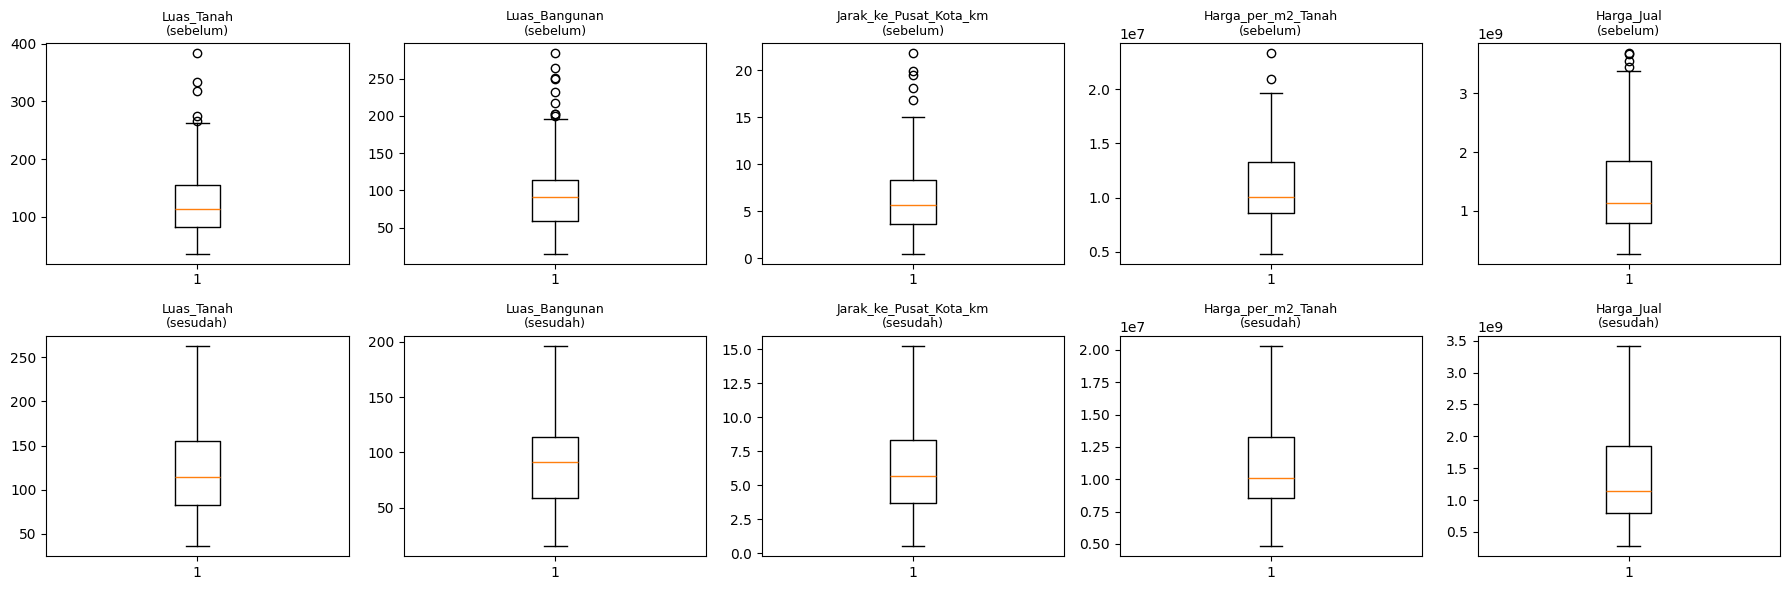

In [ ]:
kol_outlier = ['Luas_Tanah','Luas_Bangunan','Jarak_ke_Pusat_Kota_km','Harga_per_m2_Tanah','Harga_Jual']
df_sebelum_outlier = df.copy()
hasil = []
for c in kol_outlier:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[c] < bawah) | (df[c] > atas)
    hasil.append({'Kolom': c, 'Q1': q1, 'Q3': q3, 'Batas bawah': round(bawah, 1), 'Batas atas': round(atas, 1),
                  'Jumlah outlier': int(mask.sum()), 'Nilai maks sebelum': df[c].max()})
    df[c] = df[c].clip(lower=max(bawah, df[c].min()), upper=atas)
tabel_outlier = pd.DataFrame(hasil).set_index('Kolom')
tabel_outlier['Nilai maks sesudah'] = df[kol_outlier].max()
display(tabel_outlier)

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for j, c in enumerate(kol_outlier):
    axes[0, j].boxplot(df_sebelum_outlier[c]); axes[0, j].set_title(c + '\n(sebelum)', fontsize=9)
    axes[1, j].boxplot(df[c]); axes[1, j].set_title(c + '\n(sesudah)', fontsize=9)
plt.tight_layout(); plt.show()

Tahap 9. Transformasi data (dipilih dari materi dosen sesuai kondisi data)

In [ ]:
# data bersih: kolom bilangan bulat dikembalikan ke tipe int agar rapi
data = df.copy()
for c in ['Jumlah_Kamar_Tidur','Jumlah_Kamar_Mandi','Jumlah_Lantai','Tahun_Dibangun','Luas_Tanah','Luas_Bangunan','Harga_per_m2_Tanah','Harga_Jual']:
    data[c] = data[c].round().astype('int64')
data['Jarak_ke_Pusat_Kota_km'] = data['Jarak_ke_Pusat_Kota_km'].round(1)
df_bersih = data.copy()
print(data.shape)

(188, 19)


9.1 Konstruksi atribut

In [ ]:
data['Umur_Bangunan'] = 2026 - data['Tahun_Dibangun']
data['Jumlah_Fasilitas'] = data['Fasilitas'].map(lambda f: 0 if f == 'Tidak Diketahui' else len(f.split(', ')))
konstruksi = data[['Tahun_Dibangun','Umur_Bangunan','Fasilitas','Jumlah_Fasilitas']].head(5)
display(konstruksi)

,Tahun_Dibangun,Umur_Bangunan,Fasilitas,Jumlah_Fasilitas
0,2006,20,"Mushola, Taman, Water Heater",3
1,2000,26,"AC, Keamanan 24 Jam",2
2,2001,25,"AC, Taman",2
3,2015,11,"AC, Garasi, Taman, Water Heater",4
4,1997,29,Keamanan 24 Jam,1


9.2 Label Encoding

In [ ]:
peta = {}
for c in ['Kota','Tipe_Properti','Sertifikat']:
    le = LabelEncoder()
    data[c + '_Label'] = le.fit_transform(data[c])
    peta[c] = dict(zip(le.classes_, le.transform(le.classes_).tolist()))
urutan_kondisi = {'Perlu Renovasi': 0, 'Baik': 1, 'Baru': 2}
data['Kondisi_Ordinal'] = data['Kondisi'].map(urutan_kondisi)
peta['Kondisi (ordinal)'] = urutan_kondisi
peta_label = pd.DataFrame([(k, nama, kode) for k, v in peta.items() for nama, kode in v.items()],
                          columns=['Kolom','Kategori','Kode'])
display(peta_label)
display(data[['Kota','Kota_Label','Tipe_Properti','Tipe_Properti_Label','Sertifikat','Sertifikat_Label','Kondisi','Kondisi_Ordinal']].head())

,Kolom,Kategori,Kode
0,Kota,Batu,0
1,Kota,Gresik,1
2,Kota,Malang,2
3,Kota,Mojokerto,3
4,Kota,Sidoarjo,4
5,Kota,Surabaya,5
6,Kota,Tidak Diketahui,6
7,Tipe_Properti,Ruko,0
8,Tipe_Properti,Rumah,1
9,Tipe_Properti,Townhouse,2


,Kota,Kota_Label,Tipe_Properti,Tipe_Properti_Label,Sertifikat,Sertifikat_Label,Kondisi,Kondisi_Ordinal
0,Gresik,1,Rumah,1,Girik,1,Baru,2
1,Malang,2,Rumah,1,SHM,3,Baik,1
2,Batu,0,Rumah,1,SHM,3,Baru,2
3,Malang,2,Rumah,1,HGB,2,Perlu Renovasi,0
4,Surabaya,5,Rumah,1,HGB,2,Baik,1


9.3 Scaling (Z-score)

In [ ]:
fitur_skala = ['Luas_Tanah','Luas_Bangunan','Jumlah_Kamar_Tidur','Jumlah_Kamar_Mandi','Jumlah_Lantai',
               'Jarak_ke_Pusat_Kota_km','Harga_per_m2_Tanah','Umur_Bangunan','Jumlah_Fasilitas']

# skala sebelum scaling: terlihat rentang yang sangat berbeda
skala_sebelum = data[fitur_skala].agg(['min','max','mean','std']).T.round(2)
display(skala_sebelum)

# Z-score pada Luas_Tanah: manual vs library
x = data['Luas_Tanah'].astype(float)
z_manual = (x - x.mean()) / x.std()                                      # std sampel (n-1), seperti materi
z_lib = StandardScaler().fit_transform(data[['Luas_Tanah']])[:, 0]       # std populasi (n)
perbandingan_scaling = pd.DataFrame({'Asli': x, 'Z-score manual': z_manual, 'Z-score library': z_lib}).round(3)
display(perbandingan_scaling.head(6))
selisih = np.abs(z_manual - z_lib).max()
faktor = np.sqrt((len(x) - 1) / len(x))
print('Selisih maksimum manual vs library:', round(selisih, 5))
print('Penyebab: x.std() memakai pembagi n-1, StandardScaler memakai n. Faktor koreksi =', round(faktor, 5))
print('Manual / faktor sama dengan library:', np.allclose(z_manual / faktor, z_lib))

,min,max,mean,std
Luas_Tanah,36.0,263.0,122.33,54.18
Luas_Bangunan,15.0,196.0,94.72,43.18
Jumlah_Kamar_Tidur,1.0,7.0,2.81,1.49
Jumlah_Kamar_Mandi,1.0,6.0,1.93,1.31
Jumlah_Lantai,1.0,3.0,1.63,0.63
Jarak_ke_Pusat_Kota_km,0.5,15.2,6.28,3.71
Harga_per_m2_Tanah,4818000.0,20311750.0,10935789.89,3500244.11
Umur_Bangunan,1.0,31.0,15.04,8.38
Jumlah_Fasilitas,0.0,4.0,2.23,1.24


,Asli,Z-score manual,Z-score library
0,86.0,-0.671,-0.672
1,168.0,0.843,0.845
2,171.0,0.898,0.901
3,124.0,0.031,0.031
4,152.0,0.548,0.549
5,80.0,-0.781,-0.783


Selisih maksimum manual vs library: 0.00693
Penyebab: x.std() memakai pembagi n-1, StandardScaler memakai n. Faktor koreksi = 0.99734
Manual / faktor sama dengan library: True


In [ ]:
z_all = pd.DataFrame(StandardScaler().fit_transform(data[fitur_skala]), columns=[c + '_Z' for c in fitur_skala], index=data.index)
data = pd.concat([data, z_all], axis=1)
skala_sesudah = pd.DataFrame({'mean': z_all.mean(), 'std (populasi)': z_all.std(ddof=0), 'min': z_all.min(), 'max': z_all.max()}).round(3)
display(skala_sesudah)
print('Ukuran data hasil transformasi:', data.shape)

,mean,std (populasi),min,max
Luas_Tanah_Z,-0.0,1.0,-1.598,2.603
Luas_Bangunan_Z,-0.0,1.0,-1.851,2.351
Jumlah_Kamar_Tidur_Z,-0.0,1.0,-1.217,2.821
Jumlah_Kamar_Mandi_Z,-0.0,1.0,-0.713,3.118
Jumlah_Lantai_Z,-0.0,1.0,-1.011,2.184
Jarak_ke_Pusat_Kota_km_Z,-0.0,1.0,-1.563,2.410
Harga_per_m2_Tanah_Z,0.0,1.0,-1.752,2.686
Umur_Bangunan_Z,0.0,1.0,-1.680,1.909
Jumlah_Fasilitas_Z,0.0,1.0,-1.812,1.433


Ukuran data hasil transformasi: (188, 34)


Tahap 10. Validasi akhir dan penyimpanan hasil

In [ ]:
assert df_bersih.isna().sum().sum() == 0 and data.isna().sum().sum() == 0
assert df_bersih['ID_Properti'].is_unique
for c, (lo, hi) in batas.items():
    assert df_bersih[c].between(lo, hi).all(), c

ringkasan = pd.DataFrame({
    'Sebelum (data mentah)': [df_raw.shape[0], df_raw.shape[1], int(missing_awal.sum()), int(df_raw['ID_Properti'].duplicated().sum())],
    'Sesudah (data bersih)': [df_bersih.shape[0], df_bersih.shape[1], int(df_bersih.isna().sum().sum()), int(df_bersih['ID_Properti'].duplicated().sum())]},
    index=['Jumlah baris','Jumlah kolom','Sel missing (kosong + penanda teks)','ID duplikat'])
display(ringkasan)

out_bersih = df_bersih.copy()
out_bersih['Tanggal_Listing'] = out_bersih['Tanggal_Listing'].dt.strftime('%Y-%m-%d')
out_bersih.to_csv('dataset_properti_bersih.csv', index=False)
out_transform = data.copy()
out_transform['Tanggal_Listing'] = out_transform['Tanggal_Listing'].dt.strftime('%Y-%m-%d')
out_transform.to_csv('dataset_properti_transformasi.csv', index=False)
print('Tersimpan: dataset_properti_bersih.csv', out_bersih.shape, '| dataset_properti_transformasi.csv', out_transform.shape)

,Sebelum (data mentah),Sesudah (data bersih)
Jumlah baris,198,188
Jumlah kolom,19,19
Sel missing (kosong + penanda teks),143,0
ID duplikat,10,0


Tersimpan: dataset_properti_bersih.csv (188, 19) | dataset_properti_transformasi.csv (188, 34)
